# Hyperparameter tuning

Настроим XGBoost для выбранных признаков. Optuna максимизирует средний ROC-AUC двух временных фолдов. Final holdout не используется.

In [ ]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 100)
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
TARGET = "isFraud"
ID_COLUMN = "TransactionID"
SECONDS_PER_DAY = 86400
N_TRIALS = 15

project_root = Path.cwd()
if not (project_root / "data").exists():
    project_root = project_root.parent
data_dir = project_root / "data"

## 1. Данные и признаки

Используем выбранную нормализацию `D` и циклические признаки времени.

In [2]:
transaction_columns = [
    "TransactionID", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
    *[f"C{i}" for i in range(1, 15)],
    *[f"D{i}" for i in range(1, 16)],
    *[f"M{i}" for i in range(1, 10)],
]

selected_v_columns = (
    "V281 V282 V283 V289 V296 V301 V314 V1 V3 V4 V6 V8 V11 V13 V14 V17 V20 "
    "V23 V26 V27 V30 V36 V37 V40 V41 V44 V47 V48 V54 V55 V56 V59 V62 V65 V67 "
    "V68 V70 V76 V78 V80 V82 V86 V88 V89 V91 V127 V98 V99 V107 V108 V109 V111 "
    "V114 V115 V117 V120 V121 V123 V129 V130 V131 V138 V139 V142 V147 V155 V162 "
    "V165 V160 V166 V203 V207 V173 V169 V171 V174 V175 V180 V185 V198 V210 V209 "
    "V264 V223 V240 V241 V260 V277 V220 V221 V234 V238 V250 V271 V307 V284 V285 "
    "V286 V291 V303 V305 V309 V310 V312 V320 V332 V325 V335"
).split()

model_transaction_columns = transaction_columns + selected_v_columns

categorical_columns = [
    "ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain",
    *[f"M{i}" for i in range(1, 10)],
    "id_12", "id_15", "id_16", "id_23", "id_27", "id_28",
    "id_29", "id_30", "id_31", "id_33", "id_34", "id_35",
    "id_36", "id_37", "id_38", "DeviceType", "DeviceInfo",
]

identity_columns = [
    *[f"id_{i:02d}" for i in range(1, 10)],
    *[f"id_{i}" for i in range(10, 39)],
]

dtypes = {
    column: "float32"
    for column in model_transaction_columns + identity_columns
}
dtypes.update({column: "category" for column in categorical_columns})
dtypes[ID_COLUMN] = "int32"
dtypes[TARGET] = "int8"

selected_d_columns = ["D1", "D2", "D4", "D10", "D11", "D15"]

In [3]:
transactions = pd.read_csv(
    data_dir / "train_transaction.csv",
    index_col=ID_COLUMN,
    usecols=model_transaction_columns + [TARGET],
    dtype=dtypes,
)

identity = pd.read_csv(
    data_dir / "train_identity.csv",
    index_col=ID_COLUMN,
    dtype=dtypes,
)

X = transactions.join(identity, how="left")
y = X.pop(TARGET)
del transactions, identity


print("X shape:", X.shape)
print("Fraud rate:", f"{y.mean():.2%}")

X shape: (590540, 201)
Fraud rate: 3.50%


## 2. Временные фолды

| Fold | Train | Gap | Validation |
|---|---|---|---|
| 1 | дни 1–62 | 63–92 | 93–122 |
| 2 | дни 1–92 | 93–122 | 123–152 |

Дни 153–182 оставляем для финальной проверки.

In [4]:
relative_day = (X["TransactionDT"] // SECONDS_PER_DAY).astype("int16")

fold_masks = {
    "fold_1": {
        "train": relative_day.between(1, 62),
        "gap": relative_day.between(63, 92),
        "validation": relative_day.between(93, 122),
    },
    "fold_2": {
        "train": relative_day.between(1, 92),
        "gap": relative_day.between(93, 122),
        "validation": relative_day.between(123, 152),
    },
}

final_holdout_mask = relative_day.between(153, 182)

fold_summary_rows = []
for fold_name, masks in fold_masks.items():

    fold_summary_rows.append({
        "fold": fold_name,
        "train_rows": int(masks["train"].sum()),
        "validation_rows": int(masks["validation"].sum()),
        "train_fraud_rate": y.loc[masks["train"]].mean(),
        "validation_fraud_rate": y.loc[masks["validation"]].mean(),
    })

fold_summary = pd.DataFrame(fold_summary_rows).set_index("fold")
display(fold_summary.round(4))
print("Final holdout rows (not used):", int(final_holdout_mask.sum()))

Final holdout rows (not used): 85430


,train_rows,validation_rows,train_fraud_rate,validation_fraud_rate
fold,,,,
fold_1,229906,93880,0.0316,0.0400
fold_2,326186,85044,0.0338,0.0339


## 3. Подготовка данных

Feature engineering и encoding не зависят от параметров модели, поэтому готовим матрицы один раз до запуска Optuna.

In [5]:
def add_time_features(data):
    df = data.copy()

    df["hour"] = (df["TransactionDT"] // 3_600) % 24
    df["weekday"] = (df["TransactionDT"] // SECONDS_PER_DAY) % 7

    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["weekday_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
    df["weekday_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)

    return df


def normalize_selected_d_features(data, columns=selected_d_columns):
    df = data.copy()
    transaction_day = df["TransactionDT"] / SECONDS_PER_DAY

    for column in columns:
        df[column] = (df[column] - transaction_day).astype("float32")

    return df


def build_features(data):
    return normalize_selected_d_features(add_time_features(data))

In [6]:
categorical_model_columns = [
    column for column in categorical_columns
    if column in X.columns
]

sample_features = build_features(X.iloc[:1])
numeric_model_columns = [
    column for column in sample_features.columns
    if column not in categorical_model_columns
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-2,
                dtype=np.float32,
            ),
            categorical_model_columns,
        ),
        ("numeric", "passthrough", numeric_model_columns),
    ],
    verbose_feature_names_out=False,
)

fold_data = {}

for fold_name, masks in fold_masks.items():
    started = perf_counter()

    X_train_features = build_features(X.loc[masks["train"]])
    X_valid_features = build_features(X.loc[masks["validation"]])

    fold_preprocessor = clone(preprocessor)
    X_train_matrix = fold_preprocessor.fit_transform(X_train_features)
    X_valid_matrix = fold_preprocessor.transform(X_valid_features)

    fold_data[fold_name] = {
        "X_train": X_train_matrix.astype(np.float32, copy=False),
        "y_train": y.loc[masks["train"]].to_numpy(dtype=np.int8),
        "X_valid": X_valid_matrix.astype(np.float32, copy=False),
        "y_valid": y.loc[masks["validation"]].to_numpy(dtype=np.int8),
    }

    print(
        fold_name,
        X_train_matrix.shape,
        X_valid_matrix.shape,
        f"prepared in {perf_counter() - started:.1f}s",
    )

    del X_train_features, X_valid_features

del X, y, sample_features

fold_1 (229906, 207) (93880, 207) prepared in 2.6s
fold_2 (326186, 207) (85044, 207) prepared in 2.9s


## 4. Оценка параметров

Каждую конфигурацию обучаем на двух фолдах и сохраняем ROC-AUC, PR-AUC, разрыв train–validation, лучшую итерацию и время.

In [7]:
COMMON_XGB_PARAMS = {
    "eval_metric": "auc",
    "tree_method": "hist",
    "max_bin": 256,
    "verbosity": 0,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
}


def evaluate_configuration(model_params):
    fold_results = []

    for fold_name, matrices in fold_data.items():
        model = XGBClassifier(
            **COMMON_XGB_PARAMS,
            **model_params,
        )

        started = perf_counter()
        model.fit(
            matrices["X_train"],
            matrices["y_train"],
            eval_set=[(matrices["X_valid"], matrices["y_valid"])],
            verbose=False,
        )
        fit_seconds = perf_counter() - started

        train_proba = model.predict_proba(matrices["X_train"])[:, 1]
        valid_proba = model.predict_proba(matrices["X_valid"])[:, 1]

        train_roc_auc = roc_auc_score(matrices["y_train"], train_proba)
        valid_roc_auc = roc_auc_score(matrices["y_valid"], valid_proba)

        fold_results.append({
            "fold": fold_name,
            "train_roc_auc": train_roc_auc,
            "valid_roc_auc": valid_roc_auc,
            "roc_auc_gap": train_roc_auc - valid_roc_auc,
            "valid_pr_auc": average_precision_score(
                matrices["y_valid"], valid_proba
            ),
            "best_iteration": model.best_iteration,
            "fit_seconds": fit_seconds,
        })

        del model, train_proba, valid_proba

    return pd.DataFrame(fold_results)

## 5. Текущая модель

Сначала оцениваем модель из feature engineering как точку сравнения.

In [ ]:
reference_params = {
    "n_estimators": 2000,
    "max_depth": 4,
    "learning_rate": 0.01,
    "min_child_weight": 1,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "gamma": 0.0,
    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "early_stopping_rounds": 50,
}

reference_results = evaluate_configuration(reference_params)
display(reference_results.round(4))

reference_summary = {
    "mean_valid_roc_auc": reference_results["valid_roc_auc"].mean(),
    "min_valid_roc_auc": reference_results["valid_roc_auc"].min(),
    "mean_valid_pr_auc": reference_results["valid_pr_auc"].mean(),
    "mean_roc_auc_gap": reference_results["roc_auc_gap"].mean(),
}

display(pd.DataFrame([reference_summary], index=["reference"]).round(4))

,fold,train_roc_auc,valid_roc_auc,roc_auc_gap,valid_pr_auc,best_iteration,fit_seconds
0,fold_1,0.9372,0.8845,0.0528,0.5266,1999,154.0820
1,fold_2,0.9320,0.8826,0.0494,0.4914,1999,149.6679


,mean_valid_roc_auc,min_valid_roc_auc,mean_valid_pr_auc,mean_roc_auc_gap
reference,0.8835,0.8826,0.509,0.0511


## 6. Optuna

В каждом trial доступно до 4000 деревьев. Early stopping останавливает обучение, если ROC-AUC не улучшается 100 итераций.

In [ ]:
def objective(trial):
    model_params = {
        "n_estimators": 4000,
        "early_stopping_rounds": 100,
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.08, log=True
        ),
        "max_depth": trial.suggest_int("max_depth", 3, 7),
        "min_child_weight": trial.suggest_float(
            "min_child_weight", 1.0, 20.0, log=True
        ),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.50, 1.0
        ),
        "gamma": trial.suggest_float("gamma", 0.0, 2.0),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1.0, 30.0, log=True
        ),
    }

    fold_results = evaluate_configuration(model_params)

    for row in fold_results.itertuples(index=False):
        trial.set_user_attr(f"{row.fold}_train_roc_auc", row.train_roc_auc)
        trial.set_user_attr(f"{row.fold}_valid_roc_auc", row.valid_roc_auc)
        trial.set_user_attr(f"{row.fold}_roc_auc_gap", row.roc_auc_gap)
        trial.set_user_attr(f"{row.fold}_valid_pr_auc", row.valid_pr_auc)
        trial.set_user_attr(f"{row.fold}_best_iteration", row.best_iteration)
        trial.set_user_attr(f"{row.fold}_fit_seconds", row.fit_seconds)

    trial.set_user_attr(
        "min_valid_roc_auc", fold_results["valid_roc_auc"].min()
    )
    trial.set_user_attr(
        "mean_valid_pr_auc", fold_results["valid_pr_auc"].mean()
    )
    trial.set_user_attr(
        "mean_roc_auc_gap", fold_results["roc_auc_gap"].mean()
    )
    trial.set_user_attr(
        "total_fit_seconds", fold_results["fit_seconds"].sum()
    )

    return fold_results["valid_roc_auc"].mean()


def report_trial(study, trial):
    print(
        f"Trial {trial.number:02d} | "
        f"mean ROC-AUC={trial.value:.5f} | "
        f"min={trial.user_attrs['min_valid_roc_auc']:.5f} | "
        f"mean PR-AUC={trial.user_attrs['mean_valid_pr_auc']:.5f} | "
        f"gap={trial.user_attrs['mean_roc_auc_gap']:.5f} | "
        f"time={trial.user_attrs['total_fit_seconds']:.1f}s"
    )

In [10]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name="xgboost_time_cv",
)

tuning_started = perf_counter()
study.optimize(
    objective,
    n_trials=N_TRIALS,
    callbacks=[report_trial],
    gc_after_trial=True,
)
tuning_seconds = perf_counter() - tuning_started

print(f"Completed trials: {len(study.trials)}")
print(f"Total tuning time: {tuning_seconds / 60:.1f} min")

Trial 00 | mean ROC-AUC=0.89991 | min=0.89398 | mean PR-AUC=0.54477 | gap=0.07102 | time=222.9s
Trial 01 | mean ROC-AUC=0.89425 | min=0.89182 | mean PR-AUC=0.53279 | gap=0.06975 | time=98.1s
Trial 02 | mean ROC-AUC=0.89441 | min=0.88970 | mean PR-AUC=0.53507 | gap=0.06582 | time=244.3s
Trial 03 | mean ROC-AUC=0.89843 | min=0.89438 | mean PR-AUC=0.54617 | gap=0.07691 | time=179.8s
Trial 04 | mean ROC-AUC=0.89767 | min=0.89313 | mean PR-AUC=0.54253 | gap=0.07007 | time=350.4s
Trial 05 | mean ROC-AUC=0.89394 | min=0.89080 | mean PR-AUC=0.53365 | gap=0.06551 | time=381.5s
Trial 06 | mean ROC-AUC=0.88282 | min=0.88096 | mean PR-AUC=0.51607 | gap=0.05001 | time=249.8s
Trial 07 | mean ROC-AUC=0.88469 | min=0.88410 | mean PR-AUC=0.51527 | gap=0.05131 | time=541.1s
Trial 08 | mean ROC-AUC=0.89509 | min=0.89085 | mean PR-AUC=0.53636 | gap=0.06849 | time=294.5s
Trial 09 | mean ROC-AUC=0.89809 | min=0.89352 | mean PR-AUC=0.54077 | gap=0.07189 | time=298.4s
Trial 10 | mean ROC-AUC=0.89553 | min=0.8

## 7. Результаты

Optuna выбирает по среднему ROC-AUC. При финальном выборе также смотрим худший фолд и разрыв train–validation.

In [11]:
trial_rows = []

for trial in study.trials:
    if trial.state != optuna.trial.TrialState.COMPLETE:
        continue

    trial_rows.append({
        "trial": trial.number,
        "mean_valid_roc_auc": trial.value,
        "min_valid_roc_auc": trial.user_attrs["min_valid_roc_auc"],
        "mean_valid_pr_auc": trial.user_attrs["mean_valid_pr_auc"],
        "mean_roc_auc_gap": trial.user_attrs["mean_roc_auc_gap"],
        "fold1_roc_auc": trial.user_attrs["fold_1_valid_roc_auc"],
        "fold2_roc_auc": trial.user_attrs["fold_2_valid_roc_auc"],
        "fold1_pr_auc": trial.user_attrs["fold_1_valid_pr_auc"],
        "fold2_pr_auc": trial.user_attrs["fold_2_valid_pr_auc"],
        "fold1_best_iteration": trial.user_attrs["fold_1_best_iteration"],
        "fold2_best_iteration": trial.user_attrs["fold_2_best_iteration"],
        "fit_minutes": trial.user_attrs["total_fit_seconds"] / 60,
        **trial.params,
    })

experiment_table = (
    pd.DataFrame(trial_rows)
    .sort_values("mean_valid_roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(experiment_table.round(5))

,trial,mean_valid_roc_auc,min_valid_roc_auc,mean_valid_pr_auc,mean_roc_auc_gap,fold1_roc_auc,fold2_roc_auc,fold1_pr_auc,fold2_pr_auc,fold1_best_iteration,fold2_best_iteration,fit_minutes,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda
0,13,0.90217,0.89636,0.55038,0.07438,0.89636,0.90799,0.54916,0.55160,1223,2290,5.24885,0.01544,7,3.39738,0.85495,0.71617,0.06802,0.00293,14.62238
1,14,0.90143,0.89596,0.54594,0.07149,0.89596,0.90689,0.54769,0.54418,1405,1814,4.71271,0.01293,7,2.32858,0.83422,0.65748,0.79714,0.00054,12.65415
2,12,0.90070,0.89540,0.54716,0.07146,0.89540,0.90599,0.54844,0.54588,682,1024,2.74717,0.02209,7,2.90593,0.83596,0.61575,0.56933,0.00047,8.32449
3,0,0.89991,0.89398,0.54477,0.07102,0.89398,0.90584,0.54870,0.54083,1128,1317,3.71517,0.02179,7,8.96079,0.85953,0.57801,0.31199,0.00020,19.03037
4,11,0.89967,0.89397,0.54568,0.07136,0.89397,0.90537,0.54371,0.54766,820,1471,3.46037,0.02312,6,1.45845,0.84237,0.69866,0.36440,0.20457,7.35294
5,3,0.89843,0.89438,0.54617,0.07691,0.89438,0.90247,0.54600,0.54635,652,1367,2.99618,0.02582,6,1.81879,0.82998,0.79621,0.09290,0.10907,1.78601
6,9,0.89809,0.89352,0.54077,0.07189,0.89352,0.90265,0.54304,0.53850,1521,1844,4.97257,0.01012,7,8.31080,0.90515,0.88564,0.14809,0.00620,1.48304
7,4,0.89767,0.89313,0.54253,0.07007,0.89313,0.90221,0.54701,0.53806,1700,2334,5.84005,0.01145,7,18.04331,0.93294,0.65231,0.19534,0.26373,4.46847
8,10,0.89553,0.89219,0.53792,0.06851,0.89219,0.89888,0.54114,0.53470,504,751,1.95554,0.04786,6,17.71786,0.87623,0.63318,0.15914,0.00030,6.03400
9,8,0.89509,0.89085,0.53636,0.06849,0.89085,0.89933,0.54026,0.53247,1260,2354,4.90756,0.01794,5,1.52527,0.93077,0.53728,1.97377,0.72648,1.96574


In [12]:
best_mean_roc_auc = experiment_table["mean_valid_roc_auc"].max()
robust_candidates = experiment_table.loc[
    experiment_table["mean_valid_roc_auc"] >= best_mean_roc_auc - 0.0005
].copy()

selected_trial_row = (
    robust_candidates
    .sort_values(
        ["min_valid_roc_auc", "mean_roc_auc_gap", "fit_minutes"],
        ascending=[False, True, True],
    )
    .iloc[0]
)

selected_trial_number = int(selected_trial_row["trial"])
selected_trial = study.trials[selected_trial_number]
selected_params = {
    "n_estimators": 4_000,
    "early_stopping_rounds": 100,
    **selected_trial.params,
}

comparison = pd.DataFrame(
    [
        reference_summary,
        {
            "mean_valid_roc_auc": selected_trial_row["mean_valid_roc_auc"],
            "min_valid_roc_auc": selected_trial_row["min_valid_roc_auc"],
            "mean_valid_pr_auc": selected_trial_row["mean_valid_pr_auc"],
            "mean_roc_auc_gap": selected_trial_row["mean_roc_auc_gap"],
        },
    ],
    index=["reference", f"selected_trial_{selected_trial_number}"],
)

display(comparison.round(5))
print("Selected trial:", selected_trial_number)
print("Selected parameters:")
display(pd.Series(selected_params, name="value").to_frame())

Selected trial: 13
Selected parameters:


,mean_valid_roc_auc,min_valid_roc_auc,mean_valid_pr_auc,mean_roc_auc_gap
reference,0.88354,0.88262,0.50902,0.05108
selected_trial_13,0.90217,0.89636,0.55038,0.07438


,value
n_estimators,4000.000000
early_stopping_rounds,100.000000
learning_rate,0.015443
max_depth,7.000000
min_child_weight,3.397384
subsample,0.854947
colsample_bytree,0.716171
gamma,0.068017
reg_alpha,0.002929
reg_lambda,14.622376


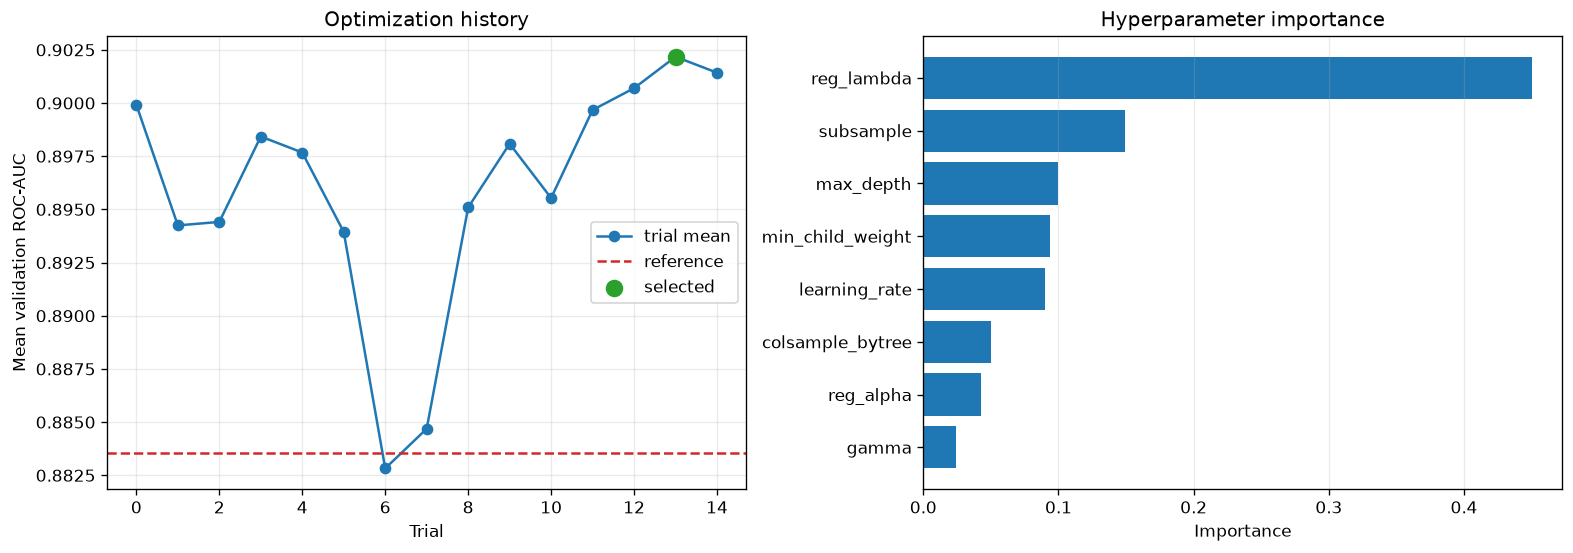

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

trial_order = experiment_table.sort_values("trial")
axes[0].plot(
    trial_order["trial"],
    trial_order["mean_valid_roc_auc"],
    marker="o",
    label="trial mean",
)
axes[0].axhline(
    reference_summary["mean_valid_roc_auc"],
    color="tab:red",
    linestyle="--",
    label="reference",
)
axes[0].scatter(
    [selected_trial_number],
    [selected_trial_row["mean_valid_roc_auc"]],
    color="tab:green",
    s=90,
    zorder=3,
    label="selected",
)
axes[0].set(
    xlabel="Trial",
    ylabel="Mean validation ROC-AUC",
    title="Optimization history",
)
axes[0].legend()
axes[0].grid(alpha=0.25)

parameter_importance = optuna.importance.get_param_importances(study)
importance_series = pd.Series(parameter_importance).sort_values()
axes[1].barh(importance_series.index, importance_series.values)
axes[1].set(
    xlabel="Importance",
    title="Hyperparameter importance",
)
axes[1].grid(axis="x", alpha=0.25)

plt.show()

## 8. Вывод

Лучшим устойчивым вариантом стал trial 13:

- средний ROC-AUC — 0.90217;
- минимальный ROC-AUC — 0.89636;
- средний PR-AUC — 0.55038;
- средний train–validation gap — 0.07438.

Параметры trial 13 зафиксированы для финальной проверки. Holdout пока не использовался.